In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, load_iris
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
f1_score, confusion_matrix, ConfusionMatrixDisplay,
classification_report, precision_recall_curve)


In [5]:
X, y = make_classification(n_samples=5000, n_features=10, n_informative=5,
                            weights=[0.95, 0.05], flip_y=0.01, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(pd.Series(y_train).value_counts(normalize=True))

0    0.945
1    0.055
Name: proportion, dtype: float64


In [8]:
def summarize(name, y_true, y_pred):
    return {"model": name, 
            "accuracy": accuracy_score(y_true, y_pred), 
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)
    }
dummy= DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)
print(summarize("Always predict majority", y_test, pred_dummy))

{'model': 'Always predict majority', 'accuracy': 0.945, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


In [ ]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
pred = model.predict(X_test)

tn, fp, fn, tp =confusion_matrix(y_test, pred).ravel()
print("TN, FP, FN, TP:", tn, fp, fn, tp)

accuracy = (tp+tn)/ (tn+fn+tp+fp)
precision = tp/(tp+fp) if (tp+fp) >0 else 0
recall = tp/(tp+fn) if (tp+fn) >0 else 0
f1= 2 * recall * precision / (precision+recall) if (precision+recall) >0 else 0


TN, FP, FN, TP: 942 3 51 4


In [11]:
print("By hand:", accuracy, precision, recall, f1)

By hand: 0.946 0.5714285714285714 0.07272727272727272 0.1290322580645161


In [17]:
print("Scikit-learn:", accuracy_score(y_test, pred), 
      precision_score(y_test, pred), 
        recall_score(y_test, pred), 
        f1_score(y_test, pred))

Scikit-learn: 0.946 0.5714285714285714 0.07272727272727272 0.12903225806451613


Text(0.5, 1.0, 'Confusion matrix (rows = actual, columns = predicted)')

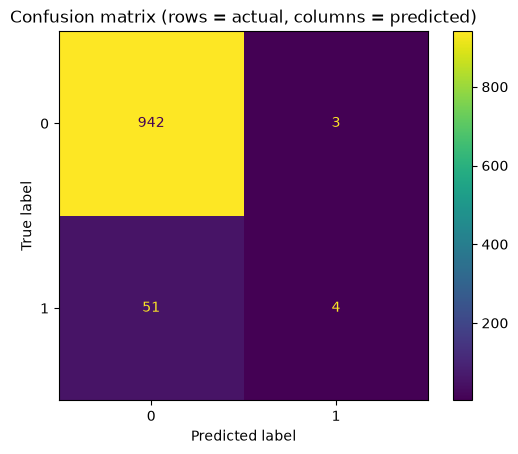

In [18]:
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.title("Confusion matrix (rows = actual, columns = predicted)")

In [19]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97       945
           1       0.57      0.07      0.13        55

    accuracy                           0.95      1000
   macro avg       0.76      0.53      0.55      1000
weighted avg       0.93      0.95      0.93      1000



In [21]:
proba_cv = cross_val_predict(model, X_train, y_train, cv=5, method="predict_proba")[:, 1]
prec, rec, thr= precision_recall_curve(y_train, proba_cv)

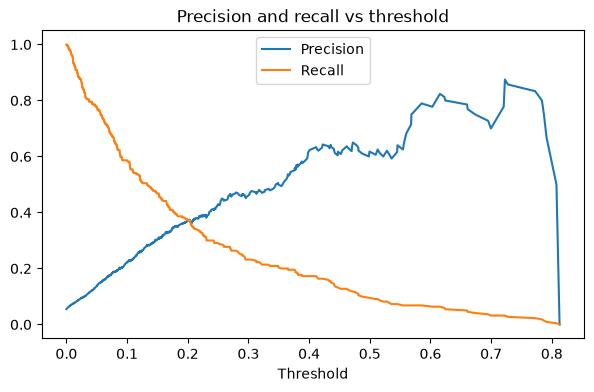

In [24]:
plt.figure(figsize=(7,4))
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.xlabel("Threshold")
plt.title("Precision and recall vs threshold")
plt.legend()

In [27]:
target_recall = 0.80
ok= rec[:-1] >= target_recall
best_thr = thr[ok].max() if ok.any() else 0.5
print("Chosen threshold:", best_thr)
proba_test = model.predict_proba(X_test)[:, 1]
pred_tuned = (proba_test >= best_thr).astype(int)

Chosen threshold: 0.03730098237408332


In [29]:
model_bal = make_pipeline(StandardScaler(), 
        LogisticRegression(max_iter=1000,class_weight="balanced"))
model_bal.fit(X_train, y_train)
pred_bal = model_bal.predict(X_test)

results = pd.DataFrame([
    summarize("Majority baseline", y_test, pred_dummy),
    summarize("Logistic (default 0.5)", y_test, pred),
    summarize("Logistic (class_weighted=balanced)", y_test, pred_bal), 
    summarize("Logistic (tuned threshold)", y_test, pred_tuned), 
]).round(3)
print(results)



                                model  accuracy  precision  recall     f1
0                   Majority baseline     0.945      0.000   0.000  0.000
1              Logistic (default 0.5)     0.946      0.571   0.073  0.129
2  Logistic (class_weighted=balanced)     0.743      0.159   0.855  0.268
3          Logistic (tuned threshold)     0.615      0.111   0.855  0.196


##### Multiclass metrics

In [31]:
Xi, yi = load_iris(return_X_y=True)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, 
                                              stratify=yi, random_state=42)

In [32]:
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xi_tr, yi_tr)
pi = clf.predict(Xi_te)
print(confusion_matrix(yi_te, pi))

[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]


In [33]:
print(classification_report(yi_te, pi))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.82      0.93      0.88        15
           2       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



In [34]:
for avg in ["macro", "micro", "weighted"]:
    print(avg, "F1:", f1_score(yi_te, pi, average=avg))

macro F1: 0.9107142857142857
micro F1: 0.9111111111111111
weighted F1: 0.9107142857142857
